In [ ]:
%cd /kaggle/working
!git clone https://@github.com/Backtodagame/Mobility_Aware_for_AGIN.git
%cd /kaggle/working/Mobility_Aware_for_AGIN/Channel_Modeling

/kaggle/working
fatal: destination path 'Mobility_Aware_for_AGIN' already exists and is not an empty directory.
/kaggle/working/Mobility_Aware_for_AGIN/Channel_Modeling


In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
# from System_Modeling_update_obs_vec import * 
from collections import deque
from tqdm import trange 
import random 
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches
import numpy as np
import torch.nn.functional as F
import Channel_FSO as ch_fso 
# import Channel_RF as ch_rf
from Parameters import *
import os 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

action_size = 5
STEP  = 20 
batch_size = 64
gamma = 0.99 # discounted factor
epsilon_start = 1.0
epsilon_min = 0.05
n_episodes = 2001
n_steps = 300
n_steps_test=1000
exploration_time = 1/4

epsilon_decay  = (epsilon_start - epsilon_min) / (exploration_time * n_episodes * n_steps)  

learning_rate = 1e-3
n_uavs = 3
n_users = 200

class DQN(nn.Module):
    """
    Deep Q-Network for UAV model

    Agrs:
        n_observation (int): observation vector for input
        n_action (int)     : UAV action
    
    Returns:
        the best action in each observation vector 
    """
    def __init__(self, n_observation, n_action):
        super().__init__()
        self.linear_relu_stack = nn.Sequential (
            nn.Linear(n_observation, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, n_action)
        )
    def forward(self, x):
        return self.linear_relu_stack(x)

def move_uav(uav_pos, action):
    """
    Action Space:
        Discrere space: the numver of possible action is finite (5)
    
    Args:
        uav_pos : uav position in tensor [(n_uavs , 2)]
        action  (int): specific number representing for action 
    
    Returns:
        uav_pos after performing action    
    """
    moved = uav_pos.clone()
    for i,a in enumerate (action):
        if a==0: moved[i][0] += STEP  # moving 1 step East 
        elif a == 1: moved[i][0] -= STEP # West
        elif a == 2: moved[i][1] += STEP # North
        elif a == 3: moved[i][1] -= STEP  # South
        else :
            pass
        moved[i][0] = torch.clip(moved[i][0],0, map_maximum_xy_axis - 1)
        moved[i][1] = torch.clip(moved[i][1],0, map_maximum_xy_axis - 1)
    return moved

def simulate_user_mobility(
        n_users, n_steps,
        distribution='gaussian', n_hotspot = n_uavs,
        ratio_mobile = 0.2,
        device ="cuda", 
        dtype = torch.float32
        ):

    """
    Simulate user mobility with 20% of them will move, while the rest
    is standing (not moving) 

    Args: 
        n_users (int) : Number of users
        n_steps (int) : Number of time steps
        map_center (float): Half of the area size 
        distribution (str) : User mobility models
        n_hotspot (int) : Number of hotspots 
        ratio_mobile (float) : Ratio of moving users and total one
    Returns:
        positions: np.ndarray of shape (n_users, n_steps, 2) 
    """

    positions = np.zeros((n_users, n_steps, 2))  
    n_mobile  = int(ratio_mobile * n_users)
    mobile_indices = np.random.choice(n_users, n_mobile, replace=False)
    static_indices = [i for i in range(n_users) if i not in mobile_indices]

    if distribution == 'gaussian':

        if n_hotspot > 1 :
            spot_centers = []

            for _ in range(n_hotspot):
                mean = np.random.uniform(300, map_center * 2 - 300,2)   
                spot_centers.append(mean)       
            spot_users = [0]

            while any(np.array(spot_users) <=0 ):
                nums = np.random.normal(n_users // n_hotspot,20,size= n_hotspot)
                spot_users = [int(num) for num in nums]
                spot_users[-1] = n_users - sum(spot_users[:-1])
            idx = 0

            for i in range(n_hotspot):
                count = spot_users[i]          
                group = np.arange(idx, idx+ count)  
                init_pos = np.random.normal(spot_centers[i], 200, (count, 2)) 
                positions[group, 0, :] = init_pos 
                idx +=count 

        else:
            mean = np.random.uniform(300, map_center * 2 -300, 2)
            positions[:,0,:] = np.random.normal(mean, 300, (n_users,2))
    elif distribution == 'uniform':
        positions[:,0,:] = np.random.uniform(0,map_center*2, (n_users, 2))


    # Clip initial positions to boundaries in map 
    positions[:,0,:] = np.clip(positions[:,0,:], 0, map_center * 2)
    positions[static_indices,:,:] = positions[static_indices, 0, :][:,None,:]

    alpha = 0.75
    avg_speed = 1.358 #m/s Men who is (20-29) age years old.  
    delta_t = 1.0 
    speeds = np.zeros(n_users)
    directions = np.random.uniform(low=0, high=360,size=n_users)
    avg_direction = directions.copy()

    
    for t in range(1,n_steps):

        s_x = np.random.normal(0,1, size=n_mobile)
        d_x = np.random.normal(0,1, size=n_mobile)

        speeds[mobile_indices]     = (alpha * speeds[mobile_indices]     + (1-alpha)* avg_speed                     + np.sqrt((1-alpha**2))*s_x)
        directions[mobile_indices] = (alpha * directions[mobile_indices] + (1-alpha)* avg_direction[mobile_indices] + np.sqrt((1-alpha**2))*d_x)

        pre_x = positions[mobile_indices, t-1, 0]
        pre_y = positions[mobile_indices, t-1, 1]

        new_x = np.round(pre_x + speeds[mobile_indices]* np.cos(np.deg2rad(directions[mobile_indices])) * delta_t ,2)
        new_y = np.round(pre_y + speeds[mobile_indices]* np.sin(np.deg2rad(directions[mobile_indices])) * delta_t ,2)
        
        limit_map = map_center * 2
        out_right = new_x > limit_map
        out_left  = new_x < 0
        out_top   = new_y > limit_map
        out_bot   = new_y < 0

        corner_upper_right = out_right & out_top        
        avg_direction[mobile_indices[corner_upper_right]] = 225
        new_x[corner_upper_right], new_y[corner_upper_right] = limit_map, limit_map

        corner_upper_left = out_left & out_top
        avg_direction[mobile_indices[corner_upper_left]] = 315
        new_x[corner_upper_left], new_y[corner_upper_left] = 0, limit_map

        corner_lower_right = out_right & out_bot
        avg_direction[mobile_indices[corner_lower_right]] = 135
        new_x[corner_lower_right], new_y[corner_lower_right] = limit_map, 0

        corner_lower_left = out_left & out_bot
        avg_direction[mobile_indices[corner_lower_left]] = 45
        new_x[corner_lower_left], new_y[corner_lower_left] = 0, 0

        edge_right = out_right & ~out_top & ~out_bot
        avg_direction[mobile_indices[edge_right]] = 180
        new_x[edge_right] = limit_map

        edge_left = out_left & ~out_top & ~out_bot
        avg_direction[mobile_indices[edge_left]] = 0 
        new_x[edge_left] = 0

        edge_top = out_top & ~out_right & ~out_left
        avg_direction[mobile_indices[edge_top]] = 270
        new_y[edge_top] = limit_map

        edge_bot = out_bot & ~out_right & ~out_left
        avg_direction[mobile_indices[edge_bot]] = 90
        new_y[edge_bot] = 0


        positions[mobile_indices, t, 0] = new_x
        positions[mobile_indices, t, 1] = new_y

    postions_3d = np.zeros((n_users, n_steps, 3))
    postions_3d[:,:,:2] = positions

    return torch.tensor(postions_3d,dtype=dtype,device=device)

def plot_user(user_positions, time_step=1):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(user_positions[:,time_step,0], user_positions[:,time_step,1], color='blue', s=8, label='Users')
    ax.set_xlim(0, map_maximum_xy_axis)
    ax.set_ylim(0, map_maximum_xy_axis)
    ax.legend()
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def build_user_heatmap(user_pos_t, device= "cuda"):
    """
    Build user heatmap from their position at time step t 

    Args:
        user_pos_t ((num_users, t, 2))
    
    Returns:
        User heatmap at specified time step ((n_cells, n_cells))
    """
    xy = user_pos_t[:,:2]
    indices = (xy / map_cell_size).long()
    indices = torch.clamp(indices, min =0, max=n_cells-1) 
    cols = indices[:,0]
    rows = indices[:,1] 
    flat_indices = rows * n_cells + cols  
    heatmap_1d = torch.bincount(flat_indices, minlength=n_cells*n_cells).float()
    heatmap = heatmap_1d.view(n_cells, n_cells)
    max_val = heatmap.max()

    if max_val > 0 :
        heatmap = heatmap / max_val
        
    return heatmap
    

def torch_get_full_cloud(clwc_range=[0.5, 7.5], device="cuda"):
    # 1. Tạo ma trận ngẫu nhiên siêu nhỏ: 6 ô dọc x 8 ô ngang
    small_noise = torch.rand((1, 1, 6, 8), device=device)
    
    # 2. Phóng to lên (1600x6400) bằng bicubic -> Mây tự mượt, không bị lốm đốm
    cloud = F.interpolate(small_noise, size=(1600, 6400), mode='bicubic', align_corners=False)
    
    # 3. Mũ 2 để đè các vùng mây mờ xuống -> Tạo thung lũng trời quang rộng lớn
    cloud = cloud ** 2
    
    # 4. Đưa về thang giá trị [0.5 -> 7.5]
    cloud_map = clwc_range[0] + cloud * (clwc_range[1] - clwc_range[0])
    cloud_map = torch.clamp(cloud_map, min=clwc_range[0], max=clwc_range[1])

    return cloud_map




def get_cloudmap_t(t, cloud_map,device="cuda"):
    """
    Get cloud map at time step t in the coordinate origin (1600, 1600)

    Args:
        t (int) : time step 
        concentrated_cloud_map (area): the cloud map which is stack by a number of its copy

    Returns:
        region_t ((area, area)): cloud map at time step t 
        cell_clwc_t ((n_cells, n_cells)): clwc value calculated in cells  
    """
    shift = int(4 * t)
    region_t = cloud_map[0,0,:,shift:shift+map_maximum_xy_axis]
    region_t_4D = region_t.unsqueeze(0).unsqueeze(0)

    cell_clwcl_t = F.avg_pool2d(
        region_t_4D,
        kernel_size=map_cell_size,
        stride=map_cell_size)
    
    cell_clwcl_t = cell_clwcl_t.squeeze() / 7.5

    return region_t, cell_clwcl_t



def cal_probability_having_LoS(vertical_dist, horizontal_dist):
    return (
        1 / (1 + a*torch.exp(-b*(180/torch.pi* torch.arctan(vertical_dist/horizontal_dist)) -a))
    )

def cal_avg_pathloss(dist_3d, p_LoS, current_fc):
    #cal path loss LoS and NLoS
    eta_LoS = 20* torch.log10(4*torch.pi*current_fc*dist_3d/ c) + xi_los
    eta_NLoS = 20* torch.log10(4*torch.pi*current_fc*dist_3d/ c) + xi_nlos

    return (
       p_LoS * eta_LoS + (1- p_LoS)*eta_NLoS
    )

def cal_dbW(dbm):
    return (
        10 ** ((dbm-30)/10)
    )
    


def cal_R_FP_batch(ue_pos_t, fp_pos,base_station='uav',device='cuda', 
                   B_RF=600e6, fc = 2e9):
    """
    Calculate Data Rate betweeen Flying Platforms (uav/hap) and users
    
    Agrs:
        ue_pos_t : user position at time step t
        fp_pos   : flying platform position
    """
    # Old: d = torch.norm(user_pos[:, :2].unsqueeze(1) - fp_pos[:, :2].unsqueeze(0), dim=2)  # (N, M)
    # New :
    if base_station == 'uav':
        vertical_dist = uav_z
        horizontal_dist = torch.linalg.norm(ue_pos_t[:,:2].unsqueeze(1) - fp_pos[:,:2],dim=2) # ([n_user, n_uav])

    elif base_station == 'hap':
        vertical_dist = hap_z
        horizontal_dist = torch.linalg.norm(ue_pos_t[:,:2].unsqueeze(1) - fp_pos[:2],dim=2) # ([n_user, 1])

    else :
        print(f"no base station was chosen")
        return -1
    
    dist_3d = torch.sqrt(horizontal_dist**2 + vertical_dist**2)

    P_los = cal_probability_having_LoS(vertical_dist , horizontal_dist )
    avg_eta = cal_avg_pathloss(dist_3d= dist_3d , p_LoS= P_los,current_fc= fc)

    avg_eta_exponent = 10** (-avg_eta / 10)

    N0_W_HZ = cal_dbW(N0)
    if base_station == 'uav':
        P_RF_W = cal_dbW(UAV_P_RF)
    elif base_station == 'hap':
        P_RF_W = cal_dbW(HAP_P_RF)
    else :
        print(f"no base station was chosen")
        return -1
    
    SNR = P_RF_W * avg_eta_exponent /  N0_W_HZ
    data_rate   = (B_RF / n_users) * torch.log2(1+SNR)

    return data_rate


def perform_user_association(uav_pos, user_pos_t, region_t, HAP_position, device ="cuda"):
    """
    Perform user association based on valid UAV range and capacity.

    Args:
        uav_pos  tensor ((num_uav, 3))          # 3 stands for x,y,z value in coordinate origin
        user_pos_t tensor ((num_users, num_step, 3))  # 3 stands for x,y,z value in coordinate origin
        region_t tensor ((area, area))
        HAP_position tensor ((1 , 3))           # 3 stands for x,y,z value in coordinate origin

    Returns:
        alpha: UE/UAV association matrix ((num_users, num_uav))
        beta : UE/HAP association tensor (num_users)
        RUAV : Total Rate per UAV       (num_uav)    
        CFSO : FSO Capacity per UAV     (num_uav)
    """
    with torch.no_grad():
        x_idx = uav_pos[:, 0].long().clamp(0, region_t.shape[1]-1)
        y_idx = uav_pos[:, 1].long().clamp(0, region_t.shape[0]-1)
        Mc = region_t[y_idx, x_idx]
        CFSO = ch_fso.Ergodic_Capacity_Trapz(
            x_higher_vehicle=HAP_position[0], y_higher_vehicle=HAP_position[1], z_higher_vehicle=HAP_position[2],
            x_lower_vehicle=uav_pos[:,0], y_lower_vehicle=uav_pos[:,1], z_lower_vehicle=uav_pos[:,2],
            Mc=Mc,link='HAP-UAV'
        )

        CFSO_remaining = CFSO.clone()
        dists = torch.linalg.norm(user_pos_t[:,:2].unsqueeze(1) - uav_pos[:,:2],dim=2) #([n_users, n_uavs])
        is_user_in_uav_range = dists <= uav_radius_coverage
        all_uav_rates = cal_R_FP_batch(ue_pos_t=user_pos_t, fp_pos= uav_pos, base_station='uav')
        hap_rates     = cal_R_FP_batch(ue_pos_t=user_pos_t, fp_pos= HAP_position, base_station='hap')
        is_uav_rate_better_than_hap = all_uav_rates > hap_rates
        valid = is_user_in_uav_range & is_uav_rate_better_than_hap  #([n_user, n_uav])
        alpha = torch.zeros((n_users,n_uavs), dtype=torch.bool,device=device)
        beta  = torch.ones(n_users, dtype=torch.bool,device=device)
        RUAV =  torch.zeros(n_uavs, dtype=torch.float32,device=device)
        valid_rates = valid * all_uav_rates
        sorted_rates, sorted_uav = torch.sort(valid_rates,dim=1,descending=True)

        for user_idx in range(n_users):
            for i in range(n_uavs):
                rate = sorted_rates[user_idx,i].item() #return float instead of tensor with one element

                if rate <=0 :
                    break

                uav_idx = sorted_uav[user_idx, i]

                if CFSO_remaining[uav_idx].item() >=rate :
                    alpha[user_idx,uav_idx] =True
                    beta[user_idx] = False
                    RUAV[uav_idx] +=rate
                    CFSO_remaining[uav_idx] -=rate
                    break # Next user 


        return alpha, beta, RUAV, CFSO
                

def calculate_rewards(RUAV, CFSO, uav_pos, Rthres=0.6e9, w=0.3 , p=0.5, device ="cuda"):
    """
    Reward Function: 
        Calculate rewards based on user association results. This stage is fundemental 
        in RL because it is the only feedback for the agent. Thanks to it, out agent knows
        if the action taken was good or not.

    Args:
        RUAV: Total rate per UAV (tensor)
        CFSO: FSO Capacity per UAV (tensor)
        uav_pos: Position of each UAV in 3 dimensions tensor (( num_uav, 3))
        Rthres: Rate threshold
        w: Global reward weight 
        p: overlap penalty

    Returns:
        rewards: List of rewards for each UAV
    """

    with torch.no_grad():
        num_uav = CFSO.shape[0]
        if not isinstance(Rthres, torch.Tensor):
            Rthres = torch.tensor(Rthres, device=device)

        # UAV overlaps
        delta = uav_pos[:,:2].unsqueeze(1) - uav_pos[:,:2].unsqueeze(0)
        dists_uav = torch.linalg.norm(delta, dim =2)
        overlaps = (dists_uav < 2* uav_radius_coverage) & (~torch.eye(n=num_uav, device=device, dtype=torch.bool))
        nc = overlaps.sum(dim=1)

        # global reward 
        total_rate = torch.sum(RUAV)
        total_capacity = torch.sum(CFSO)
        thres = num_uav * Rthres
        sqrt_sum = torch.sqrt((total_rate * total_capacity/ thres**2))
        g_reward = sqrt_sum - (0.0 if torch.all(RUAV > Rthres) else 1.0)

        # local reward 
        sqrt_term = torch.sqrt((RUAV / Rthres) * (CFSO/Rthres))
        l_reward  = torch.where(RUAV > Rthres, sqrt_term -nc*p, sqrt_term - nc*p -1) 

        #total reward
        total_reward = w * g_reward + (1-w) * l_reward

        return total_reward.tolist()


def user_association_and_calculate_reward(uav_pos, user_pos_t, region_t, HAP_position ,device ="cuda"):
    """
    Perform user association, then calculate reward (combining perform_user_association and calculating rewards functions) 

    Args:
        uav_pos: UAV position (tensor)
        user_pos_t: user position at time step t (tensor)
        region_t: clwc map at time step t 
        HAP_position: HAP position (tensor)

    Returns:
        rewards : 
        alpha: UE/UAV association matrix ((num_users, num_uav))
        beta : UE/HAP association tensor (num_users)
        RUAV : Total Rate per UAV       (num_uav)
        CFSO : FSO Capacity per UAV (num_uav)    
    """

    alpha, beta, RUAV, CFSO = perform_user_association(uav_pos, user_pos_t, region_t,HAP_position,device=device)
    rewards = calculate_rewards(RUAV, CFSO,uav_pos,device=device)

    return rewards, alpha, beta, RUAV, CFSO


def build_observation_vector_without_cloud(uav_pos, user_pos_t, cell_clwc_t, alpha, beta, device="cuda"):
    """
    Build the observation input vector (a.k.a Observation Space)

    Args: 
        uav_pos  (( num_uav, 3)) : Position of each UAV in 3 dimensions torch
        user_pos_t : Position of users in a specific time step
        cell_clwc_t (( n_cells, n_cells)): cell clwc value
        alpha    (( num_users, num_uav))
        beta     (num_uav) 
    Returns:
        Observation space vector with shape torch.Tensor ((3,130))
    """

    obs_list = []
    normalized_uav_xy = uav_pos[:,:2] / map_maximum_xy_axis

    if (n_uavs==1):
        served_mask = (alpha[:,0] ==1 ) | (beta ==1)   # | is OR operator   
        # print(served_mask.shape)     
        served_users_xy = user_pos_t[served_mask]
        user_heatmap = build_user_heatmap(served_users_xy) 
        # other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
        obs_vector  = torch.concatenate([normalized_uav_xy.flatten(), user_heatmap.flatten()])
        obs_list.append(obs_vector)

        obs_batch = torch.stack(obs_list, axis=0)
    else :
        for i in range(n_uavs):
            served_mask = (alpha[:, i] ==1 ) | (beta ==1)   # | is OR operator        
            # print(served_mask.shape)     

            served_users_xy = user_pos_t[served_mask]
            user_heatmap = build_user_heatmap(served_users_xy) 
            other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
            obs_vector  = torch.concatenate([normalized_uav_xy[i],other_uav_pos.flatten(), user_heatmap.flatten()])
            obs_list.append(obs_vector)
        obs_batch = torch.stack(obs_list, axis=0)

    return obs_batch


def build_observation_vector_w_cloud(uav_pos, user_pos_t, cell_clwc_t, alpha, beta, device="cuda"):
    """
    Build the observation input vector (a.k.a Observation Space)

    Args: 
        uav_pos  (( num_uav, 3)) : Position of each UAV in 3 dimensions torch
        user_pos_t : Position of users in a specific time step
        cell_clwc_t (( n_cells, n_cells)): cell clwc value
        alpha    (( num_users, num_uav))
        beta     (num_uav) 
    Returns:
        Observation space vector with shape torch.Tensor ((3,130))
    """

    obs_list = []
    normalized_uav_xy = uav_pos[:,:2] / map_maximum_xy_axis

    if (n_uavs==1):
        served_mask = (alpha[:,0] ==1 ) | (beta ==1)   # | is OR operator   
        # print(served_mask.shape)     
        served_users_xy = user_pos_t[served_mask]
        user_heatmap = build_user_heatmap(served_users_xy) 
        # other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
        obs_vector  = torch.concatenate([normalized_uav_xy.flatten(), user_heatmap.flatten(), cell_clwc_t.flatten()])
        obs_list.append(obs_vector)

        obs_batch = torch.stack(obs_list, axis=0)
    else :
        for i in range(n_uavs):
            served_mask = (alpha[:, i] ==1 ) | (beta ==1)   # | is OR operator        
            # print(served_mask.shape)     

            served_users_xy = user_pos_t[served_mask]
            user_heatmap = build_user_heatmap(served_users_xy) 
            other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
            obs_vector  = torch.concatenate([normalized_uav_xy[i],other_uav_pos.flatten(), user_heatmap.flatten(), cell_clwc_t.flatten()])
            obs_list.append(obs_vector)
        obs_batch = torch.stack(obs_list, axis=0)

    return obs_batch


def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)


def evaluate_trained_policy(
    device=device, 
    save_dir = '/kaggle/working/save_models',
    episode_to_load =str(n_episodes-1),
    n_steps_test= n_steps_test,
    use_cloud_state=True
):
    """
    Evaluate trained policy

    Args:
        DQN: Deep Q Network that is used to train 
        action_size: action size of UAV
        n_uavs: number of uav
        n_steps_test: total steps to test
        uav_pos_init: initial uav position
        user_pos: user position
        cloud_map: cloud map 
        hap_pos: hap position 
        episode to load: which episode to evaluate 
        save_dir: save directory in kaggle 
    
    Returns:
        RUAV_log: Total Data Rate served by UAV
        CFSO_log: Allocated FSO to UAV
        uav_traj: uav trajectory 
    """
    set_seed(42)

    total_cells = (map_maximum_xy_axis // map_cell_size) **2
    if use_cloud_state :
        Q_nets = [DQN(2*n_uavs+total_cells*2,action_size).to(device) for i in range(n_uavs)]   #    2 + total_cells**2 is equal the number of length [x_uav, y_uav, user heatmap, cloud heatmap]
        for i in range(n_uavs):
            path = f"{save_dir}/q_net_uav{i}_ep{episode_to_load}_w_cloud.pt"
            Q_nets[i].load_state_dict(torch.load(path, map_location = device))
            Q_nets[i].eval()
            print(f"Q_net_with_cloud")
            print(Q_nets[i])
    
    else :
        Q_nets = [DQN(2*n_uavs+total_cells,action_size).to(device) for i in range(n_uavs)]   #    2 + total_cells**2 is equal the number of length [x_uav, y_uav, user heatmap, cloud heatmap]
        for i in range(n_uavs):
            path = f"{save_dir}/q_net_uav{i}_ep{episode_to_load}_no_cloud.pt"
            Q_nets[i].load_state_dict(torch.load(path, map_location = device))
            Q_nets[i].eval()
            print(f"Q_net_without_cloud")
            print(Q_nets[i])



    hap_pos = torch.tensor([map_maximum_xy_axis/2, map_maximum_xy_axis/2,hap_z], dtype= torch.float32,device=device)
    cloud_map = torch_get_full_cloud()
    
    user_pos = simulate_user_mobility(n_users, n_steps_test)
    uav_pos = torch.randint(0,map_maximum_xy_axis, (n_uavs, 3),dtype=torch.float32, device=device )
    uav_pos[:,2] = uav_z

    region_0, cell_clwc_0 = get_cloudmap_t(0,cloud_map)
    user_pos_0 = user_pos[:,0,:]
    rewards0, alpha0, beta0, RUAV0, CFSO0 = user_association_and_calculate_reward(
        uav_pos, user_pos_0, region_0, hap_pos,device
    )
    if use_cloud_state :
        obs_vec = build_observation_vector_w_cloud(
            uav_pos, user_pos_0, cell_clwc_0, alpha0, beta0
            ) # ([3,130]) # 3 stands for n_uavs, 130 stands for obs_vec length
    else:
        obs_vec = build_observation_vector_without_cloud(
            uav_pos, user_pos_0, cell_clwc_0, alpha0, beta0
            ) # ([3,130]) # 3 stands for n_uavs, 130 stands for obs_vec length
    hap_rates     = cal_R_FP_batch(ue_pos_t=user_pos_0, fp_pos= hap_pos, base_station='hap')
    hap_log = []

    hap_log.append(hap_rates.sum().item())

    uav_rewards, RUAV_log, CFSO_log, uav_traj, alpha_log = [],[],[],[],[]
    uav_rewards.append(rewards0)
    RUAV_log.append(RUAV0.cpu().numpy().copy())
    CFSO_log.append(CFSO0.cpu().numpy().copy())
    uav_traj.append(uav_pos.cpu().numpy().copy())
    alpha_log.append(alpha0.cpu().numpy().copy())

    total_rates= (hap_rates.squeeze() * beta0.float()).sum() + RUAV0.sum()
    total_rates_log = []
    total_rates_log.append(total_rates.item()) 

    for t in range(n_steps_test):

        with torch.no_grad():
            actions = [Q_nets[i](obs_vec[i]).argmax().item() for i in range(n_uavs)]

        uav_pos = move_uav(uav_pos, actions)
        next_t = min(t+1, n_steps_test -1)
        next_region_t, next_cell_clwc_t = get_cloudmap_t(next_t, cloud_map)
        next_user_pos_t = user_pos[:,next_t,:]
        rewards, alpha, beta, RUAV, CFSO = user_association_and_calculate_reward(
            uav_pos, next_user_pos_t, next_region_t, hap_pos, device
        )
        if use_cloud_state:
            obs_vec = build_observation_vector_w_cloud(
                uav_pos, next_user_pos_t, next_cell_clwc_t,alpha, beta
                )
        else :
            obs_vec = build_observation_vector_without_cloud(
                uav_pos, next_user_pos_t, next_cell_clwc_t,alpha, beta
                )
            
        hap_rates     = cal_R_FP_batch(ue_pos_t=next_user_pos_t, fp_pos= hap_pos, base_station='hap')
        hap_log.append(hap_rates.sum().item())
        total_rates= (hap_rates.squeeze() * beta.float()).sum() + RUAV.sum()
        total_rates_log.append(total_rates.item()) 
        uav_rewards.append(rewards)
        RUAV_log.append(RUAV.cpu().numpy().copy())
        CFSO_log.append(CFSO.cpu().numpy().copy())
        uav_traj.append(uav_pos.cpu().numpy().copy())
        alpha_log.append(alpha.cpu().numpy().copy())


    return RUAV_log, CFSO_log, uav_traj, uav_rewards, cloud_map, hap_pos, user_pos, alpha_log, hap_log, total_rates_log


if __name__ == "__main__":
    _,_,_,_,_,_,_,_,hap_log_no_cloud, total_rate_no_cloud= evaluate_trained_policy(save_dir='/kaggle/input/models/trisleevawnminh/model-without-cloud/pytorch/default/1',use_cloud_state=False)
    _,_,_,_,_,_,_,_,hap_log_w_cloud, total_rate_w_cloud= evaluate_trained_policy(save_dir='/kaggle/input/models/trisleevawnminh/model-w-cloud/pytorch/default/1',use_cloud_state=True)
    

Q_net_without_cloud
DQN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=70, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=5, bias=True)
  )
)
Q_net_without_cloud
DQN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=70, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=5, bias=True)
  )
)
Q_net_without_cloud
DQN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=70, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): R

In [22]:
print(np.mean(hap_log_no_cloud))
print(np.mean(hap_log_w_cloud))

233769130.7092907
233769130.7092907


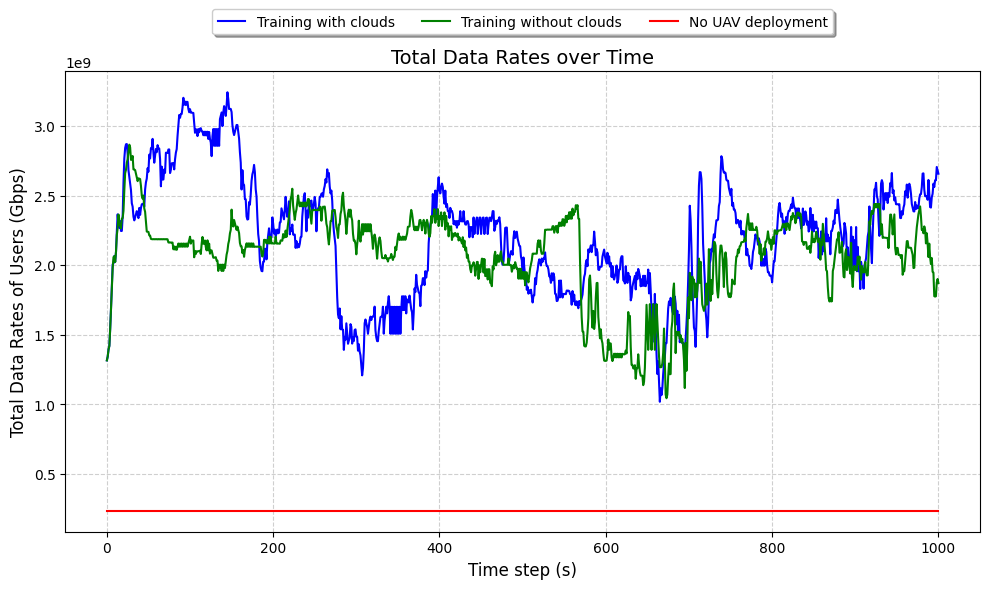

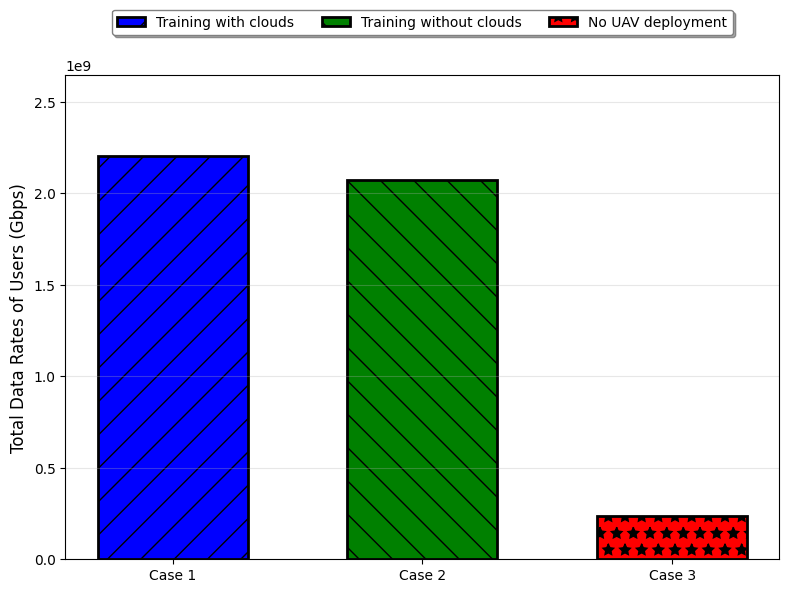

In [23]:
# ==============================================================
    # 3. VẼ BIỂU ĐỒ (b): TỔNG THÔNG LƯỢNG THEO THỜI GIAN (LINE PLOT)
    # ==============================================================
plt.figure(figsize=(10, 6))

# Vẽ các đường
plt.plot(total_rate_w_cloud, label="Training with clouds", color="blue", linewidth=1.5)
plt.plot(total_rate_no_cloud, label="Training without clouds", color="green", linewidth=1.5)
plt.plot(hap_log_w_cloud, label="No UAV deployment", color="red", linewidth=1.5)

# Định dạng biểu đồ
plt.xlabel("Time step (s)", fontsize=12)
plt.ylabel("Total Data Rates of Users (Gbps)", fontsize=12)
plt.title("Total Data Rates over Time", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)

# Đặt Legend ở trên cùng (ngoài biểu đồ) giống ảnh gốc
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=3, shadow=True, fancybox=True)

plt.tight_layout()
plt.savefig("benchmark_time_series.png", dpi=300)
plt.show()

# ==============================================================
# 4. VẼ BIỂU ĐỒ (c): THÔNG LƯỢNG TRUNG BÌNH (BAR CHART)
# ==============================================================
# Tính trung bình của từng mảng
mean_aware = np.mean(total_rate_w_cloud)
mean_unaware = np.mean(total_rate_no_cloud)
mean_no_uav = np.mean(hap_log_w_cloud)

cases = ['Case 1', 'Case 2', 'Case 3']
means = [mean_aware, mean_unaware, mean_no_uav]

# Định nghĩa các nhãn tương ứng cho chú thích
labels = ['Training with clouds', 'Training without clouds', 'No UAV deployment']

plt.figure(figsize=(8, 6))

# Lặp qua từng case để vẽ từng cột riêng biệt nhằm gán label dễ dàng
bars = []
hatches = ['/', '\\', '*']
colors = ['blue', 'green', 'red']
for i in range(len(cases)):
    bar = plt.bar(cases[i], means[i], color=colors[i], edgecolor='black', 
                  linewidth=2, width=0.6, hatch=hatches[i], label=labels[i])
    bars.append(bar)

# Định dạng trục
plt.ylabel("Total Data Rates of Users (Gbps)", fontsize=12)

# Thiết lập lưới
plt.grid(axis='y', linestyle='-', alpha=0.3)

# Giới hạn trục Y (tùy chỉnh cho đẹp, ví dụ bắt đầu từ 0.5 giống ảnh gốc)
max_y = max(means) * 1.2
plt.ylim(0, max_y)

# Thêm chú thích (Legend)
# Sử dụng bbox_to_anchor để đưa chú thích lên phía trên biểu đồ
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), 
           ncol=3, shadow=True, fancybox=True, edgecolor='gray')

plt.tight_layout()
plt.savefig("benchmark_bar_chart.png", dpi=300)
plt.show()